In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict


In [4]:
df = pd.read_csv("Connections.csv", skiprows=3)
df.columns = ["First Name","Last Name","URL","Email","Company","Position","Connected On"]

print(f"Total connections: {len(df)}")
print(df.head())


Total connections: 233
  First Name                         Last Name  \
0      Yawar                             Abbas   
1    Charles                      JANIER-DUBRY   
2     Tomasz  Rogala MBA, PMP, CMgr MCMI, IEng   
3    Zelalem                      Anely Birhan   
4     Juraij                           Sadaqat   

                                                 URL  \
0  https://www.linkedin.com/in/yawar-abbas-6871aa244   
1  https://www.linkedin.com/in/charles-janier-dub...   
2           https://www.linkedin.com/in/tomaszrogala   
3  https://www.linkedin.com/in/zelalem-anely-birh...   
4  https://www.linkedin.com/in/juraij-sadaqat-b92...   

                       Email  \
0                        NaN   
1                        NaN   
2                        NaN   
3                        NaN   
4  juraijmughal378@gmail.com   

                                             Company  \
0                                          Bricklinx   
1                                 

In [5]:
# Create directed graph
G = nx.Graph()

# Add ego node
G.add_node("Ego", type="ego")

# Add alter nodes and ego-to-alter edges
for _, row in df.iterrows():
    name = f"{row['First Name']} {row['Last Name']}"
    G.add_node(name, company=row["Company"], position=row["Position"])
    G.add_edge("Ego", name)

# Add inferred alter-alter edges (same company)
company_groups = df.groupby("Company")[["First Name","Last Name"]].apply(
    lambda x: [f"{r['First Name']} {r['Last Name']}" for _, r in x.iterrows()]
)
for company, members in company_groups.items():
    if len(members) >= 2:
        for i in range(len(members)):
            for j in range(i+1, len(members)):
                G.add_edge(members[i], members[j])

print(f"Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}")


Nodes: 215, Edges: 258


In [6]:
# Basic graph metrics
print("Graph density:", nx.density(G))
print("Is connected:", nx.is_connected(G))

# Remove ego and analyze components
G_no_ego = G.copy()
G_no_ego.remove_node("Ego")
components = list(nx.connected_components(G_no_ego))
print(f"Components (no ego): {len(components)}")
print(f"Largest component: {max(len(c) for c in components)} nodes")


Graph density: 0.011214953271028037
Is connected: True
Components (no ego): 190
Largest component: 7 nodes


In [7]:
# Compute centrality measures
degree_cent     = nx.degree_centrality(G)
between_cent    = nx.betweenness_centrality(G)
closeness_cent  = nx.closeness_centrality(G)

# Top 10 by betweenness (excluding ego)
sorted_between = sorted(
    [(n, v) for n, v in between_cent.items() if n != "Ego"],
    key=lambda x: -x[1]
)[:10]

for node, score in sorted_between:
    print(f"{node}: {score:.4f}")


Yawar Abbas: 0.0000
Charles JANIER-DUBRY: 0.0000
Tomasz Rogala MBA, PMP, CMgr MCMI, IEng: 0.0000
Zelalem Anely Birhan: 0.0000
Juraij Sadaqat: 0.0000
Alia Mushtaq: 0.0000
Noor Ul Ain Khursheed: 0.0000
Muhammad Hashim: 0.0000
Miguel Reyes-Nakasone: 0.0000
Seungkyu Choi: 0.0000


In [8]:
# Find all maximal cliques
cliques = list(nx.find_cliques(G_no_ego))
large_cliques = [c for c in cliques if len(c) >= 2]
large_cliques.sort(key=lambda x: -len(x))

print("Top cliques:")
for c in large_cliques[:5]:
    print(f"  Size {len(c)}: {c}")


Top cliques:
  Size 7: ['Jihyeon Ryu', 'Soyoung Jeong', 'Seungwoo Yoo', 'Byung-Kwan Lee', 'Taekyung Heo', 'Seung Wook Kim', 'Hope Gil']
  Size 3: ['Woojun Choi', 'sangyeob kim', 'kyeongwon jeong']
  Size 3: ['Yuki Kurisu', 'Kaito Kojima', 'Dahye Kim']
  Size 3: ['Ipoom Jeong', 'Seungkyu Choi', '선준 황']
  Size 3: ['Minhyuk Sung', 'Minsoo Rhu', 'Kijung Shin']


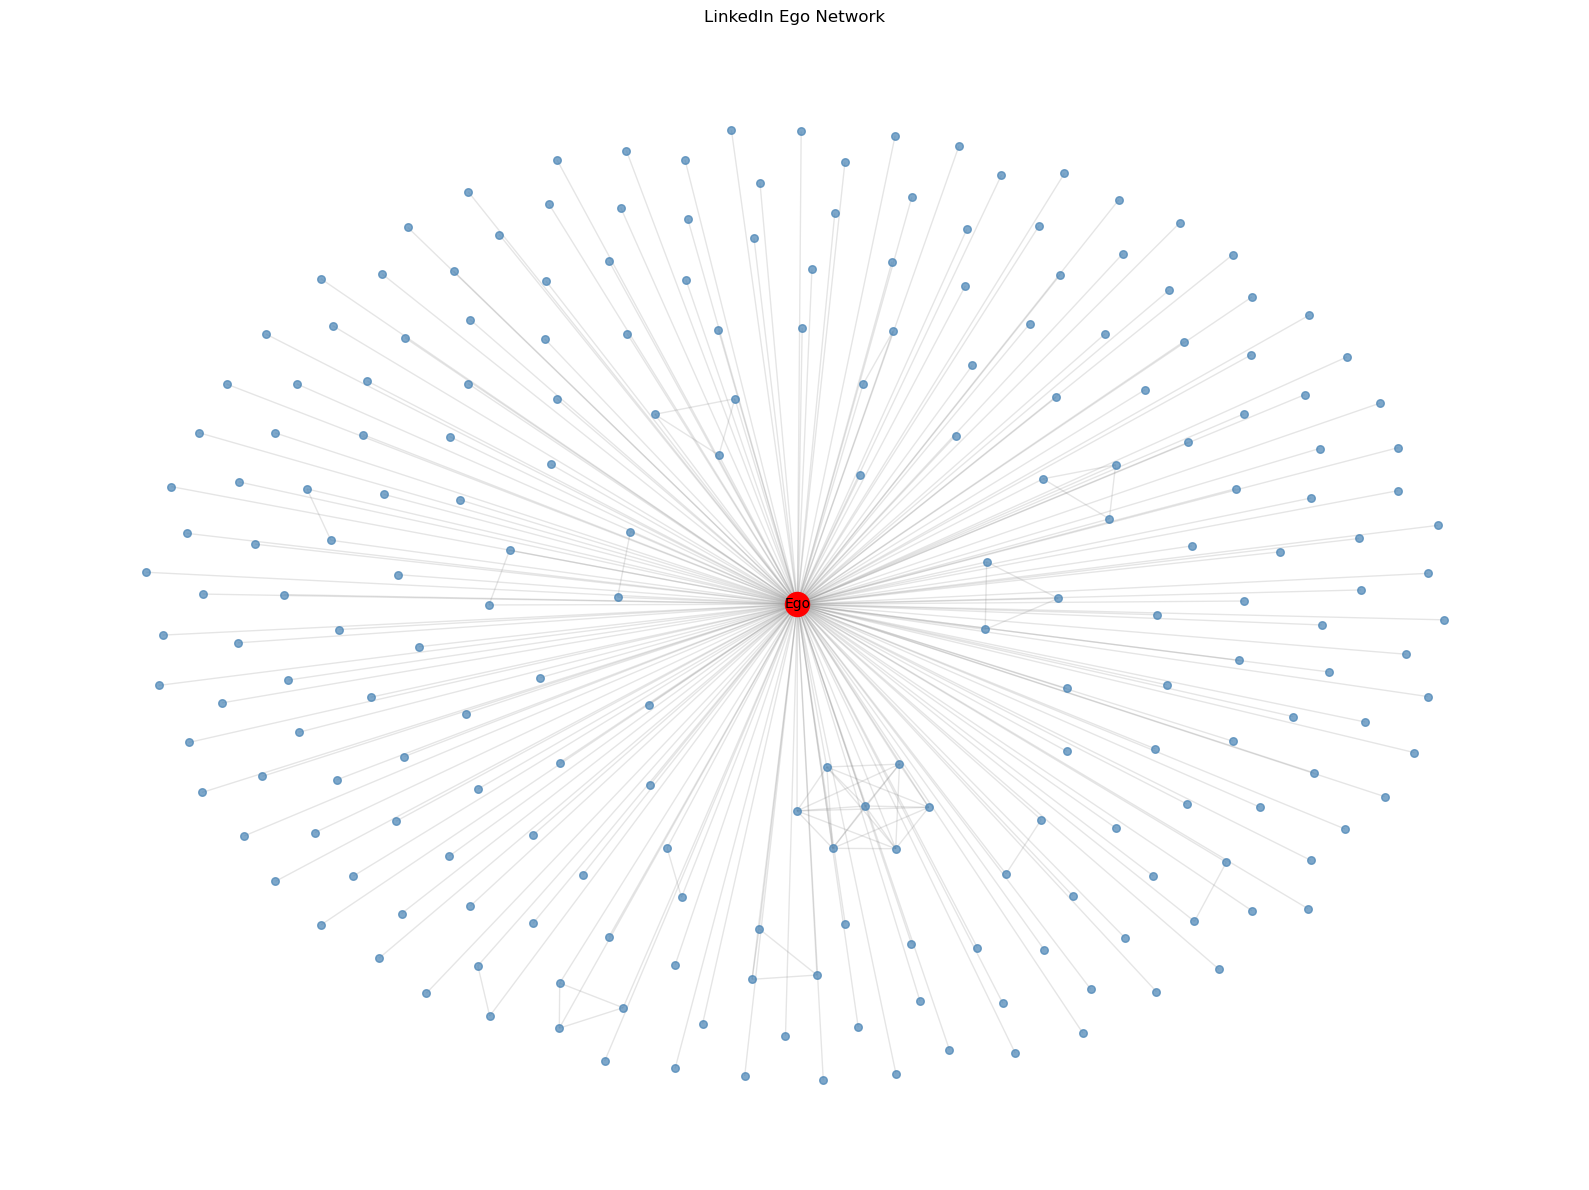

In [9]:
# Draw network with spring layout
plt.figure(figsize=(16, 12))
pos = nx.spring_layout(G, seed=42, k=0.3)

# Color by community
node_colors = []
community_map = {"Ego": "red"}  # populate from domain classifier

nx.draw_networkx_nodes(G, pos, node_size=30, node_color="steelblue", alpha=0.7)
nx.draw_networkx_nodes(G, pos, nodelist=["Ego"], node_size=300,
                       node_color="red")
nx.draw_networkx_edges(G, pos, alpha=0.2, edge_color="gray")
nx.draw_networkx_labels(G, pos, labels={"Ego": "Ego"}, font_size=10)

plt.title("LinkedIn Ego Network")
plt.axis("off")
plt.tight_layout()
plt.savefig("network.png", dpi=150)
plt.show()
